# LLM summaries: do they give the spoiler away?

A clickbait post hides one piece of information. This notebook asks the same six LLMs to **summarize** the linked article and checks whether the summary reveals that information. Two kinds of summary:
- **generic:** a two-sentence summary of the article alone (the model never sees the post). Does an ordinary summary already spoil the clickbait?
- **spoiler:** a two-sentence summary written for the post, asked to tell the reader what the post teases. This is the summary the demo shows next to the extracted spoiler.

Each summary is checked three ways:
1. **text match:** does the gold spoiler appear in the summary, word for word (exact), or nearly (fuzzy, rapidfuzz ≥ 85)? Strict: a correct paraphrase doesn't count.
2. **LLM judge:** Claude Sonnet 5.5 sees the post, the gold spoiler and the summary (not the article) and answers *yes* / *partly* / *no*: does a reader of the summary learn the spoiler? This counts paraphrases.
3. **human rating** on a small sample: the notebook writes a blinded rating sheet; the team fills it in, and the last section compares the human labels with the judge.

**Sample:** 200 test posts, stratified by spoiler type. **Prompts:** zero-shot, in `spoilerqa/summaries.py`; same settings as the spoiler runs (temperature 0 locally, low effort / low reasoning in the cloud, JSON output `{"summary": ...}`).

**How to run it** (from `milestone4/code`, with Ollama running and the API keys in `.env`, as for `1-prompted-llms.ipynb`):
```bash
caffeinate -i jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 4-summaries.ipynb
```
- 2 kinds × 6 models × 200 posts = 2,400 summaries, plus 2,400 judgments. The local models take about 1 hour (one request at a time); the cloud models a few minutes each (direct requests, several at a time).
- Cost at standard prices, estimated from the smoke test: about $3 for the summaries (mostly Sonnet and Sol, about $1.30 each) and $3–4 for the judge. The last section reports the measured cost.
- Answers are saved as they arrive (`output/summaries/raw/`), so re-running continues where it stopped.

**Smoke test:** `SMOKE=1 jupyter nbconvert --to notebook --execute 4-summaries.ipynb --output smoke-summaries.ipynb` (6 posts, the cheapest model per backend, Claude Haiku as judge; writes to `smoke/`).

## Setup

Imports, the API keys from `.env`, the models that are available, the post sample, and the settings:
- `SUMMARY_N`: posts to summarize (200);
- `JUDGE`: the judge model (Claude Sonnet 5.5);
- `RATE_N`, `RATE_ITEMS`: the human-rating sample, 30 posts × 3 summaries (GPT-6.1 Sol and GPT-OSS 20B spoiler summaries, and GPT-6.1 Sol's generic summary).

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from sklearn.metrics import cohen_kappa_score

from spoilerqa import llm
from spoilerqa import summaries as S
from spoilerqa.compare import PROMPTED
from spoilerqa.data import DEFAULT_DATA_DIR, TYPES, build_context, load_jsonl, load_split, post_text, spoiler_type
from spoilerqa.metrics import as_text
from spoilerqa.tables import to_markdown

# API keys (ANTHROPIC_API_KEY, OPENAI_API_KEY) from a git-ignored .env here in code/ or in the project root
load_dotenv(Path(".env"))
load_dotenv(Path.cwd().resolve().parents[1] / ".env")
pd.set_option("display.max_colwidth", 120)

SMOKE = os.environ.get("SMOKE", "0") == "1"
DATA_DIR = Path(os.environ.get("DATA_DIR", DEFAULT_DATA_DIR))
OUTPUT_DIR = Path("smoke/output") if SMOKE else Path("../output")
SUM_DIR = OUTPUT_DIR / "summaries"
RAW_DIR = SUM_DIR / "raw"
FIG_DIR = OUTPUT_DIR / "figures"
for d in (RAW_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

test = load_split(DATA_DIR, "test")
SUMMARY_N = 6 if SMOKE else 200
sample = llm.stratified_sample(test, SUMMARY_N, seed=2)
gold = {r["uuid"]: r for r in sample}
VARIANTS = list(S.VARIANTS)

SMOKE_MODELS = {"llama3.1-8b", "claude-haiku-5.5", "gpt-6-luna"}  # the cheapest model of each backend
availability = {key: llm.backend_available(key) for key in llm.MODELS}
MODELS = [key for key, (ok, _) in availability.items() if ok and (not SMOKE or key in SMOKE_MODELS)]
JUDGE = "claude-haiku-5.5" if SMOKE else "claude-sonnet-5.5"
RATE_N = 3 if SMOKE else 30
RATE_ITEMS = [("gpt-6-luna", "spoiler"), ("llama3.1-8b", "spoiler"), ("gpt-6-luna", "generic")] if SMOKE else \
             [("gpt-6.1-sol", "spoiler"), ("gpt-oss-20b", "spoiler"), ("gpt-6.1-sol", "generic")]
print("models:", MODELS, "| judge:", JUDGE, f"(available: {availability[JUDGE][0]})")
print(f"{len(sample)} posts:", pd.Series([spoiler_type(r) for r in sample]).value_counts().to_dict())


def save_table(df, name, digits=3):
    df.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)
    (OUTPUT_DIR / f"{name}.md").write_text(to_markdown(df, digits=digits))

/opt/anaconda3/envs/NLP/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


models: ['llama3.1-8b', 'gpt-oss-20b', 'claude-sonnet-5.5', 'claude-haiku-5.5', 'gpt-6.1-sol', 'gpt-6-luna'] | judge: claude-sonnet-5.5 (available: True)
200 posts: {'phrase': 84, 'passage': 81, 'multi': 35}


## The prompts

The two summary prompts and the judge prompt, with one filled-in example (the article is shortened here for display).

In [2]:
for name, system in [("generic summary", S.SYSTEM_GENERIC), ("spoiler summary", S.SYSTEM_SPOILER), ("judge", S.SYSTEM_JUDGE)]:
    print(f"=== {name}\n{system}\n")
system, messages = S.summary_prompt(sample[0], "spoiler")
print("=== example user message (spoiler summary)\n" + messages[0]["content"][:700] + " [...]\n")
system, messages = S.judge_prompt(sample[0], "<the summary>")
print("=== example judge message\n" + messages[0]["content"])

=== generic summary
You summarize news articles. Write a summary of the article in at most two sentences (about 50 words) for a reader who has not read it.

Reply with JSON only: {"summary": "..."}

=== spoiler summary
You get a clickbait post and the article it links to. The post teases something without saying it. Write a summary of the article in at most two sentences (about 50 words) that also tells the reader exactly what the post is teasing, so they don't need to click.

Reply with JSON only: {"summary": "..."}

=== judge
You check whether a summary gives away the spoiler of a clickbait post. You get the post, its spoiler (the information the post hides, taken from the article; a post that promises several things has a spoiler with several parts) and a summary of the article.

Answer "yes" if a reader of the summary learns the spoiler, in any wording. Answer "partly" if they learn only part of it (for example some parts of a several-part spoiler, or a vaguer version). Otherwise a

## 1. Write the summaries

Every model writes both kinds of summary for every post. The cloud models go first (direct requests, several at a time), then the local models one after the other. Each answer is appended to `output/summaries/raw/<model>_<kind>.jsonl` as it arrives.

In [3]:
def summary_file(model, variant):
    return RAW_DIR / f"{model}_{variant}.jsonl"


ordered = sorted(MODELS, key=lambda m: llm.MODELS[m]["backend"] == "ollama")  # cloud first
for model in ordered:
    for variant in VARIANTS:
        prompts = {r["uuid"]: S.summary_prompt(r, variant) for r in sample}
        llm.ask_all(model, prompts, summary_file(model, variant), schema=S.SUMMARY_SCHEMA, schema_name="summary",
                    batch=False)

summaries = {}
for model in MODELS:
    for variant in VARIANTS:
        rows = {row["uuid"]: row for row in load_jsonl(summary_file(model, variant))}
        summaries[(model, variant)] = {u: S.parse_field(rows[u]["text"], "summary") for u in gold if u in rows}
missing = {f"{m}/{v}": sum(s is None for s in d.values()) + len(gold) - len(d) for (m, v), d in summaries.items()}
print("posts without a readable summary:", {k: v for k, v in missing.items() if v} or "none")

claude-sonnet-5.5_generic: 200 done, 0 to ask
claude-sonnet-5.5_spoiler: 200 done, 0 to ask
claude-haiku-5.5_generic: 200 done, 0 to ask
claude-haiku-5.5_spoiler: 200 done, 0 to ask
gpt-6.1-sol_generic: 200 done, 0 to ask
gpt-6.1-sol_spoiler: 200 done, 0 to ask
gpt-6-luna_generic: 200 done, 0 to ask
gpt-6-luna_spoiler: 200 done, 0 to ask
llama3.1-8b_generic: 200 done, 0 to ask
llama3.1-8b_spoiler: 200 done, 0 to ask
gpt-oss-20b_generic: 200 done, 0 to ask
gpt-oss-20b_spoiler: 200 done, 0 to ask
posts without a readable summary: none


## 2. The judge

The judge reads the post, the gold spoiler and one summary, and answers whether the summary reveals the spoiler. Posts without a readable summary are skipped (and count as *no* below). Answers go to `output/summaries/raw/judge-<judge>_<model>_<kind>.jsonl`.

In [4]:
def judge_file(model, variant):
    return RAW_DIR / f"judge-{JUDGE}_{model}_{variant}.jsonl"


judgments = {}
for (model, variant), texts in summaries.items():
    prompts = {u: S.judge_prompt(gold[u], t) for u, t in texts.items() if t}
    rows = llm.ask_all(JUDGE, prompts, judge_file(model, variant), schema=S.JUDGE_SCHEMA, schema_name="judgment",
                       batch=False)
    judgments[(model, variant)] = {u: S.parse_field(row["text"], "reveals") for u, row in rows.items()}

judge-claude-sonnet-5.5_llama3.1-8b_generic: 200 done, 0 to ask
judge-claude-sonnet-5.5_llama3.1-8b_spoiler: 200 done, 0 to ask
judge-claude-sonnet-5.5_gpt-oss-20b_generic: 200 done, 0 to ask
judge-claude-sonnet-5.5_gpt-oss-20b_spoiler: 200 done, 0 to ask
judge-claude-sonnet-5.5_claude-sonnet-5.5_generic: 200 done, 0 to ask
judge-claude-sonnet-5.5_claude-sonnet-5.5_spoiler: 200 done, 0 to ask
judge-claude-sonnet-5.5_claude-haiku-5.5_generic: 200 done, 0 to ask
judge-claude-sonnet-5.5_claude-haiku-5.5_spoiler: 200 done, 0 to ask
judge-claude-sonnet-5.5_gpt-6.1-sol_generic: 200 done, 0 to ask
judge-claude-sonnet-5.5_gpt-6.1-sol_spoiler: 200 done, 0 to ask
judge-claude-sonnet-5.5_gpt-6-luna_generic: 200 done, 0 to ask
judge-claude-sonnet-5.5_gpt-6-luna_spoiler: 200 done, 0 to ask


## 3. Results

One row per (model, kind of summary):
- **words:** median summary length;
- **text: exact / fuzzy:** the mean share of gold spoiler items found in the summary as text (a multi spoiler with 2 of 4 items present counts 0.5);
- **judge: yes / partly / no:** the judge's verdicts (missing summaries count as *no*);
- **judge yes, by type:** the *yes* share per gold spoiler type.

Saved as `output/summaries-results.csv` and `.md`; the chart (judge verdicts per model and kind) as `output/figures/summaries-judge.png`.

,model,summary,posts,words,text: exact,text: fuzzy,judge: yes,judge: partly,judge: no,"judge yes, phrase","judge yes, passage","judge yes, multi"
0,llama3.1-8b,generic,200,38.000,0.360,0.386,0.735,0.195,0.070,0.929,0.716,0.314
1,llama3.1-8b,spoiler,200,35.000,0.358,0.394,0.705,0.220,0.075,0.940,0.654,0.257
2,gpt-oss-20b,generic,200,50.000,0.363,0.387,0.765,0.210,0.025,0.940,0.716,0.457
3,gpt-oss-20b,spoiler,200,47.000,0.356,0.384,0.820,0.125,0.055,0.988,0.802,0.457
4,claude-sonnet-5.5,generic,200,47.000,0.353,0.377,0.820,0.160,0.020,0.976,0.765,0.571
5,claude-sonnet-5.5,spoiler,200,49.000,0.397,0.446,0.900,0.080,0.020,1.000,0.864,0.743
6,claude-haiku-5.5,generic,200,48.000,0.339,0.371,0.800,0.155,0.045,0.952,0.778,0.486
7,claude-haiku-5.5,spoiler,200,49.000,0.356,0.414,0.865,0.105,0.030,0.976,0.840,0.657
8,gpt-6.1-sol,generic,200,47.000,0.350,0.375,0.790,0.190,0.020,0.976,0.753,0.429
9,gpt-6.1-sol,spoiler,200,46.000,0.386,0.404,0.900,0.080,0.020,1.000,0.889,0.686


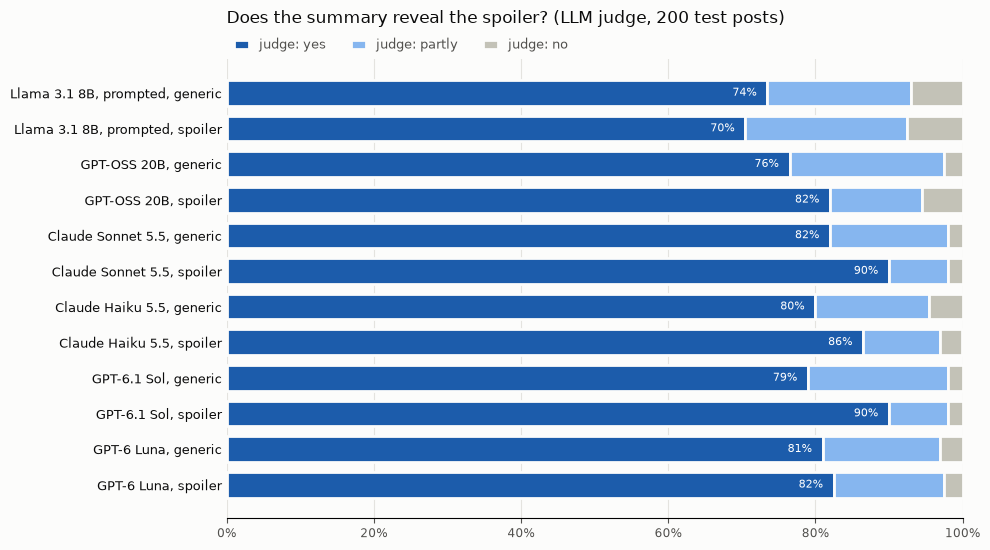

In [5]:
result_rows = []
for (model, variant), texts in summaries.items():
    verdicts = pd.Series({u: judgments[(model, variant)].get(u) or "no" for u in gold})
    text_hits = pd.DataFrame([S.spoiler_in_summary(texts.get(u) or "", gold[u]["spoiler"]) for u in gold],
                             index=list(gold), columns=["exact", "fuzzy"])
    row = {"model": model, "summary": variant, "posts": len(gold),
           "words": float(np.median([S.words(t) for t in texts.values() if t])),
           "text: exact": float(text_hits["exact"].mean()), "text: fuzzy": float(text_hits["fuzzy"].mean()),
           **{f"judge: {label}": float((verdicts == label).mean()) for label in S.JUDGE_LABELS}}
    for t in TYPES:
        ids = [u for u in gold if spoiler_type(gold[u]) == t]
        row[f"judge yes, {t}"] = float((verdicts[ids] == "yes").mean())
    result_rows.append(row)
results = pd.DataFrame(result_rows)
save_table(results, "summaries-results")
display(results.style.format(precision=3))

VERDICT_COLORS = {"yes": "#1c5cab", "partly": "#86b6ef", "no": "#c3c2b7"}  # an ordered scale: dark = reveals more
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
NAMES = {m["key"]: m["label"] for m in PROMPTED}
rows_shown = results.iloc[::-1].reset_index(drop=True)  # first model at the top
labels = [f"{NAMES.get(m, m)}, {v}" for m, v in zip(rows_shown["model"], rows_shown["summary"])]
y = np.arange(len(rows_shown))
fig, ax = plt.subplots(figsize=(10, 5.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
left = np.zeros(len(rows_shown))
for label in S.JUDGE_LABELS:
    values = rows_shown[f"judge: {label}"].to_numpy()
    ax.barh(y, values, 0.72, left=left, color=VERDICT_COLORS[label], edgecolor=SURFACE, linewidth=2,
            label=f"judge: {label}", zorder=2)
    left += values
for yi, v in zip(y, rows_shown["judge: yes"]):  # label the "yes" share inside its segment
    ax.text(v - 0.015, yi, f"{v:.0%}", va="center", ha="right", fontsize=8, color="#ffffff", zorder=3)
ax.set_yticks(y, labels, fontsize=9, color=INK)
ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", colors=INK_2, labelsize=8.5)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlim(0, 1)
ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.set_title("Does the summary reveal the spoiler? (LLM judge, 200 test posts)", loc="left", color=INK, fontsize=12, pad=26)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=9, labelcolor=INK_2,
          handlelength=1.2, borderaxespad=0.2)
fig.tight_layout()
fig.savefig(FIG_DIR / "summaries-judge.png", dpi=200, facecolor=SURFACE)
plt.show()

## 4. Examples

Four posts (one or two per type) with the gold spoiler and every model's spoiler summary, followed by the judge's verdict.

In [6]:
show = llm.stratified_sample(sample, 4, seed=5)
pd.DataFrame([{"post": post_text(r), "gold": as_text(r["spoiler"]),
               **{m: f"{summaries[(m, 'spoiler')].get(r['uuid'])} [{judgments[(m, 'spoiler')].get(r['uuid'])}]" for m in MODELS}}
              for r in show])

,post,gold,llama3.1-8b,gpt-oss-20b,claude-sonnet-5.5,claude-haiku-5.5,gpt-6.1-sol,gpt-6-luna
0,Do people look like their names?,"Yonat Zwebner, a new mother with especially good reason to agonize: Her own research suggests that people come to lo...","A study found that people can accurately guess a person's name based on their appearance, suggesting that there may ...","The article explains that researchers found people tend to resemble the names they are given: in experiments, partic...","Yes, according to research by Yonat Zwebner and colleagues at Hebrew University, IDC Herzliya and HEC Paris: people ...",The post teases whether people look like their names. The article reports research by Yonat Zwebner and colleagues f...,"Research suggests people may come to look like their names: In experiments, volunteers shown a headshot and four or ...","Research suggests people may come to resemble their names: in experiments, volunteers matched a person’s headshot to..."
1,Former mayor tweets poetry after heart attack scare,R.T. Rybak,"Former Minneapolis Mayor R.T. Rybak suffered a heart attack while cross-country skiing, but made light of the situat...","The post teases that former Minneapolis mayor R.T. Rybak, after a heart‑attack scare while cross‑country skiing, pos...",Former Minneapolis Mayor R.T. Rybak had a massive heart attack while cross-country skiing and was hospitalized. From...,Former Minneapolis Mayor R.T. Rybak suffered a heart attack while cross-country skiing and was hospitalized. From th...,"Former Minneapolis Mayor R.T. Rybak suffered a massive heart attack while cross-country skiing, just days after leav...","Former Minneapolis Mayor R.T. Rybak suffered a massive heart attack while cross-country skiing, but tweeted that he ..."
2,"Oscars 2017: 10 things you need to know, from the epic mix-up to Viola Davis’s speech",1) Faye Dunaway announced the wrong winner for best picture. 2) Viola Davis’s speech. 3) Jimmy Kimmel’s monologue. 4...,"The 2017 Oscars ceremony was marked by a major mix-up in the best picture category, where 'La La Land' was initially...","The article lists the top ten moments from the 2017 Oscars, highlighting the infamous winner mix‑up when Faye Dunawa...","The ten things to know about the 2017 Oscars: Faye Dunaway wrongly announced ""La La Land"" as best picture when ""Moon...","The post teases the 2017 Oscars' 'epic mix-up': presenter Faye Dunaway announced La La Land as best picture winner, ...",Faye Dunaway mistakenly announced “La La Land” as the 2017 Best Picture winner before “Moonlight” was confirmed; Vio...,"At the 2017 Oscars, Faye Dunaway mistakenly announced *La La Land* as best picture before the award was corrected to..."
3,"At First, Her Tattoo Reads ""I'm Fine."" Now Watch What Happens When She Stands Up...","from another angle, it can read ""save me.""","A college student got a tattoo that appears to say 'I'm fine' from most angles, but actually reads 'save me' from an...",The article explains how a woman’s ambigram tattoo—reading “I’m fine” from one angle and “save me” from another—spar...,"Miles's tattoo is an ambigram that reads ""I'm fine"" from most angles but reads ""save me"" when viewed upside down, sy...","A woman named Miles got a tattoo ambigram that reads ""I'm fine"" normally but ""save me"" when viewed from another angl...","Miles’s tattoo is an ambigram: it reads “I’m fine” one way and “save me” when viewed upside down, revealing the hidd...","Inspired by her professor’s openness about mental illness, Miles got an ambigram tattoo that reads “I’m fine” from o..."


## 5. Human rating sheet

For a small human check, the notebook writes three files to `output/summaries/`:
- **`human-rating-sheet.csv`:** `RATE_N` posts × the summaries in `RATE_ITEMS`, shuffled, without model names (blind). Columns to fill: `reveals` (yes / partly / no, as the judge), `faithful` (1–5: everything in the summary is supported by the article) and `fluent` (1–5), plus optional `notes`. The `article` column holds the article text for the faithfulness check.
- **`human-rating-key.csv`:** which model and kind of summary each row is. Raters shouldn't open it.
- **`human-rating-instructions.md`:** the instructions for the raters.

Each rater saves a filled copy as `output/summaries/human-ratings-<initials>.csv`. The sheet is only written once, so re-running the notebook never overwrites ratings in progress.

In [7]:
SHEET, KEY = SUM_DIR / "human-rating-sheet.csv", SUM_DIR / "human-rating-key.csv"
INSTRUCTIONS = SUM_DIR / "human-rating-instructions.md"
rate_items = [(m, v) for m, v in RATE_ITEMS if (m, v) in summaries]
if SHEET.exists():
    print(f"{SHEET} already exists; not overwritten")
elif rate_items:
    rate_posts = llm.stratified_sample(sample, RATE_N, seed=7)
    rows = []
    for r in rate_posts:
        for m, v in rate_items:
            rows.append({"uuid": r["uuid"], "model": m, "summary kind": v, "post": post_text(r), "gold spoiler": " | ".join(r["spoiler"]),
                         "summary": summaries[(m, v)].get(r["uuid"]) or "", "article": llm.cut_article(build_context(r))})
    sheet = pd.DataFrame(rows).sample(frac=1, random_state=11).reset_index(drop=True)
    sheet.insert(0, "row", np.arange(1, len(sheet) + 1))
    sheet[["row", "uuid", "model", "summary kind"]].to_csv(KEY, index=False)
    blind = sheet[["row", "post", "gold spoiler", "summary"]].copy()
    blind["reveals"], blind["faithful"], blind["fluent"], blind["notes"] = "", "", "", ""
    blind["article"] = sheet["article"]
    blind.to_csv(SHEET, index=False)
    INSTRUCTIONS.write_text(
        "# Rating the summaries\n\n"
        "Each row of `human-rating-sheet.csv` is a clickbait post, its spoiler (the information the post hides; "
        "several parts are separated by |) and a two-sentence summary of the article written by a language model. "
        "Fill in three columns, then save your copy as `human-ratings-<your initials>.csv` in this folder.\n\n"
        "- **reveals**: `yes` if a reader of the summary learns the spoiler (in any wording), `partly` if they learn only "
        "part of it (some parts of a several-part spoiler, or a vaguer version), otherwise `no`.\n"
        "- **faithful** (1-5): 5 = everything in the summary is supported by the article (column `article`); "
        "1 = it states something wrong or invented.\n"
        "- **fluent** (1-5): 5 = clear, natural English; 1 = hard to read.\n"
        "- **notes** (optional): anything odd.\n\n"
        "Rate each row on its own; the rows are shuffled and don't say which model wrote them. Don't open "
        "`human-rating-key.csv`.\n")
    print(f"wrote {SHEET} ({len(sheet)} rows), {KEY} and {INSTRUCTIONS}")

../output/summaries/human-rating-sheet.csv already exists; not overwritten


## 6. Human ratings vs the judge

Reads every filled sheet (`output/summaries/human-ratings-*.csv`) and reports:
- the mean **faithful** and **fluent** ratings and the **reveals** shares per model and kind of summary;
- **agreement with the judge** on *reveals*: raw agreement and Cohen's κ (chance-corrected; above 0.6 is usually read as substantial), and the same for the strict text match (fuzzy item share of 1 = *yes*, above 0 = *partly*, 0 = *no*);
- with two or more raters, **agreement between raters** (κ on *reveals*).

Nothing is printed until a filled sheet exists.

In [8]:
rating_files = sorted(SUM_DIR.glob("human-ratings-*.csv"))
if not rating_files or not KEY.exists():
    print("no filled rating sheets yet: see output/summaries/human-rating-instructions.md")
else:
    key = pd.read_csv(KEY)
    ratings = []
    for path in rating_files:
        r = pd.read_csv(path)[["row", "reveals", "faithful", "fluent"]]
        r["rater"] = path.stem.removeprefix("human-ratings-")
        ratings.append(r.merge(key, on="row"))
    ratings = pd.concat(ratings, ignore_index=True)
    ratings["reveals"] = ratings["reveals"].astype(str).str.strip().str.lower()
    ratings = ratings[ratings["reveals"].isin(S.JUDGE_LABELS)]
    ratings["judge"] = [judgments[(m, v)].get(u) or "no" for m, v, u in zip(ratings["model"], ratings["summary kind"], ratings["uuid"])]

    def text_label(m, v, u):
        share = S.spoiler_in_summary(summaries[(m, v)].get(u) or "", gold[u]["spoiler"])[1]
        return "yes" if share == 1 else "partly" if share > 0 else "no"

    ratings["text match"] = [text_label(m, v, u) for m, v, u in zip(ratings["model"], ratings["summary kind"], ratings["uuid"])]
    summary_by_item = ratings.groupby(["model", "summary kind"]).agg(
        ratings=("row", "size"), faithful=("faithful", "mean"), fluent=("fluent", "mean"),
        reveals_yes=("reveals", lambda s: (s == "yes").mean()), reveals_partly=("reveals", lambda s: (s == "partly").mean())).reset_index()
    display(summary_by_item.style.format(precision=3))
    agreement = pd.DataFrame([{"compared with humans": name, "ratings": len(ratings),
                               "agreement": float((ratings["reveals"] == ratings[col]).mean()),
                               "Cohen's kappa": cohen_kappa_score(ratings["reveals"], ratings[col], labels=S.JUDGE_LABELS)}
                              for name, col in [(f"LLM judge ({JUDGE})", "judge"), ("text match (fuzzy)", "text match")]])
    save_table(summary_by_item, "summaries-human-ratings")
    save_table(agreement, "summaries-human-vs-judge")
    display(agreement.style.format(precision=3))
    raters = ratings["rater"].unique()
    if len(raters) >= 2:
        pivot = ratings.pivot_table(index="row", columns="rater", values="reveals", aggfunc="first").dropna()
        print("agreement between raters (Cohen's kappa on reveals):",
              {f"{a} vs {b}": round(cohen_kappa_score(pivot[a], pivot[b], labels=S.JUDGE_LABELS), 3)
               for i, a in enumerate(raters) for b in raters[i + 1:]})

no filled rating sheets yet: see output/summaries/human-rating-instructions.md


## 7. Cost

What this notebook's API calls cost, from the token counts (direct requests, standard prices): summaries per model, and the judge.

In [9]:
def files_cost(model, paths):
    return sum(llm.run_cost(load_jsonl(p), llm.MODELS[model]["model"]) or 0 for p in paths if p.exists())


cost_rows = [{"what": f"summaries: {m}", "US$": files_cost(m, [summary_file(m, v) for v in VARIANTS])}
             for m in MODELS if llm.MODELS[m]["backend"] != "ollama"]
cost_rows.append({"what": f"judge: {JUDGE}", "US$": files_cost(JUDGE, RAW_DIR.glob(f"judge-{JUDGE}_*.jsonl"))})
cost = pd.DataFrame(cost_rows)
print(f"total: ${cost['US$'].sum():.2f}")
cost.style.format(precision=2)

total: $5.54


,what,US$
0,summaries: claude-sonnet-5.5,1.47
1,summaries: claude-haiku-5.5,0.07
2,summaries: gpt-6.1-sol,0.87
3,summaries: gpt-6-luna,0.04
4,judge: claude-sonnet-5.5,3.08
